# ML Forecasting with Gradient Boosting and Honest Backtesting

**What you'll learn**

- How to **reframe forecasting as supervised learning**: lag features, shifted rolling
  statistics, calendar encodings, and promo covariates on a multi-SKU retail panel —
  the setup behind most production demand-forecasting systems (and the M5 winners).
- The **leakage minefield**: we build an off-by-one rolling-feature leak on purpose,
  watch it inflate "held-out" accuracy, then show the model collapse when the feature
  is computed the only way it *can* be computed at prediction time.
- **Recursive vs direct multi-step forecasting** with LightGBM — both implemented, with
  error-accumulation curves over a 28-day horizon.
- A **rolling-origin backtest harness** that pits the ML model against seasonal naive and
  ETS — and shows **both regimes honestly**: ML wins with covariates and many related
  series; classical wins on a short, clean univariate series (trees can't extrapolate).
- **Global vs per-SKU models**: sample efficiency, cold-start behavior for late-launch
  SKUs, and where hierarchical reconciliation fits.
- **Probabilistic forecasts** with LightGBM quantile regression (P10/P50/P90), pinball
  loss, and an empirical coverage check — because inventory decisions consume quantiles,
  not point forecasts.

**Why it matters in interviews**

- "How would you forecast 10,000 SKUs daily?" is a standard senior system-design screen.
  The expected answer is a *global* ML model + feature pipeline + rolling-origin
  evaluation + baselines — exactly this notebook.
- "How do you prevent leakage in time-series features?" separates candidates who have
  shipped forecasts from those who have only done Kaggle. The shift-before-roll rule and
  "computable at prediction time" test are the core of the answer.
- "When do you need quantile forecasts?" probes whether you connect forecasts to the
  decisions they feed (safety stock, staffing) rather than stopping at RMSE.
- "Your fancy model lost to seasonal naive — why?" has a concrete answer you'll be able
  to demonstrate, not hand-wave.

Prerequisites: baselines, ETS, rolling-origin evaluation and MASE from
`02_classical_forecasting` in this folder. The quantile forecasts built here are the
input to inventory optimization (newsvendor / safety stock) — see notebook 04 in
`../09_finance_and_operations/`.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tools.sm_exceptions import ConvergenceWarning

rng = np.random.default_rng(42)

# ETS is refit dozens of times inside backtest loops; a few fits hit the optimizer's
# iteration cap on awkward series. We record the fits' results rather than let per-fit
# warnings spam the notebook.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning, module="statsmodels")

plt.rcParams.update({
    "figure.figsize": (9.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 3)

LGB_PARAMS = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=63,
    min_child_samples=20, subsample=0.9, subsample_freq=1,
    colsample_bytree=0.9, random_state=42, verbose=-1,
)

## 1. A simulated multi-SKU retail panel with known ground truth

Per the lab's data policy we simulate, so every later claim can be checked against the
generating process. The panel mimics daily units sold for 24 SKUs over ~3 years:

- **Scale heterogeneity**: base demand is lognormal across SKUs (~10 to ~400 units/day)
  — exactly why scale-free metrics (MASE) and scale-carrying features matter.
- **Trend**: per-SKU exponential drift (mean +10%/yr, some SKUs declining).
- **Weekly seasonality**: a shared weekend-heavy day-of-week profile, perturbed per SKU.
- **Yearly seasonality**: per-SKU amplitude, peaking near mid-December.
- **Promos**: multi-day promo blocks (~11% of days) with per-SKU multiplicative lift of
  1.4–2.2×. Crucially, promos are *planned* — the calendar is known in advance, so it
  is a legitimate covariate at prediction time.
- **Counts with overdispersion**: gamma-mixed Poisson, so noise scales with level.
- **Cold start**: the last 5 SKUs launch on day 800 (March of the final year) — ~9
  months of history and, importantly, **no December on record**. The panel ends
  mid-December, so the final forecast horizon covers the holiday ramp they have never
  seen. They will make the global-vs-per-SKU comparison concrete.

In [2]:
N_SKU, N_DAYS, H = 24, 1078, 28
dates = pd.date_range("2022-01-03", periods=N_DAYS, freq="D")  # starts on a Monday
t_idx = np.arange(N_DAYS)
doy = dates.dayofyear.to_numpy()
dow = dates.dayofweek.to_numpy()

base_level = rng.lognormal(np.log(60), 0.9, N_SKU)          # median ~60 units/day
growth = rng.normal(0.10, 0.12, N_SKU) / 365.0              # per-day log drift
dow_base = np.array([0.95, 0.90, 0.92, 0.98, 1.06, 1.20, 0.99])  # Mon..Sun, weekend-heavy
dow_fac = dow_base * np.exp(rng.normal(0, 0.06, (N_SKU, 7)))
dow_fac /= dow_fac.mean(axis=1, keepdims=True)
yr_amp = rng.uniform(0.10, 0.35, N_SKU)
yr_peak = rng.normal(350, 12, N_SKU)                        # peak day-of-year ~ mid-Dec
promo_lift = rng.uniform(1.40, 2.20, N_SKU)


def promo_calendar(n_days, r):
    """Multi-day promo blocks (3-7 days) with gaps; ~11% of days on promo."""
    on = np.zeros(n_days, dtype=int)
    d = 0
    while d < n_days:
        if r.random() < 0.03:
            length = int(r.integers(3, 8))
            on[d:d + length] = 1
            d += length + int(r.integers(3, 15))
        else:
            d += 1
    return on


launch_day = np.zeros(N_SKU, dtype=int)
launch_day[-5:] = 800                                        # late-launch cohort

frames = []
for i in range(N_SKU):
    promo = promo_calendar(N_DAYS, rng)
    mu = (base_level[i] * np.exp(growth[i] * t_idx) * dow_fac[i, dow]
          * (1 + yr_amp[i] * np.cos(2 * np.pi * (doy - yr_peak[i]) / 365.25))
          * promo_lift[i] ** promo)
    y = rng.poisson(mu * rng.gamma(16.0, 1 / 16.0, N_DAYS)).astype(float)
    f = pd.DataFrame({"sku": f"SKU_{i:02d}", "date": dates, "promo": promo, "y": y})
    frames.append(f.iloc[launch_day[i]:])

panel = pd.concat(frames, ignore_index=True)
LATE_SKUS = sorted(panel["sku"].unique())[-5:]
print(f"panel: {len(panel):,} rows, {panel['sku'].nunique()} SKUs, "
      f"{panel['date'].min().date()} .. {panel['date'].max().date()}")
print(f"promo share: {panel['promo'].mean():.1%};  late-launch SKUs: {LATE_SKUS}")

panel: 21,872 rows, 24 SKUs, 2022-01-03 .. 2024-12-15
promo share: 11.1%;  late-launch SKUs: ['SKU_19', 'SKU_20', 'SKU_21', 'SKU_22', 'SKU_23']


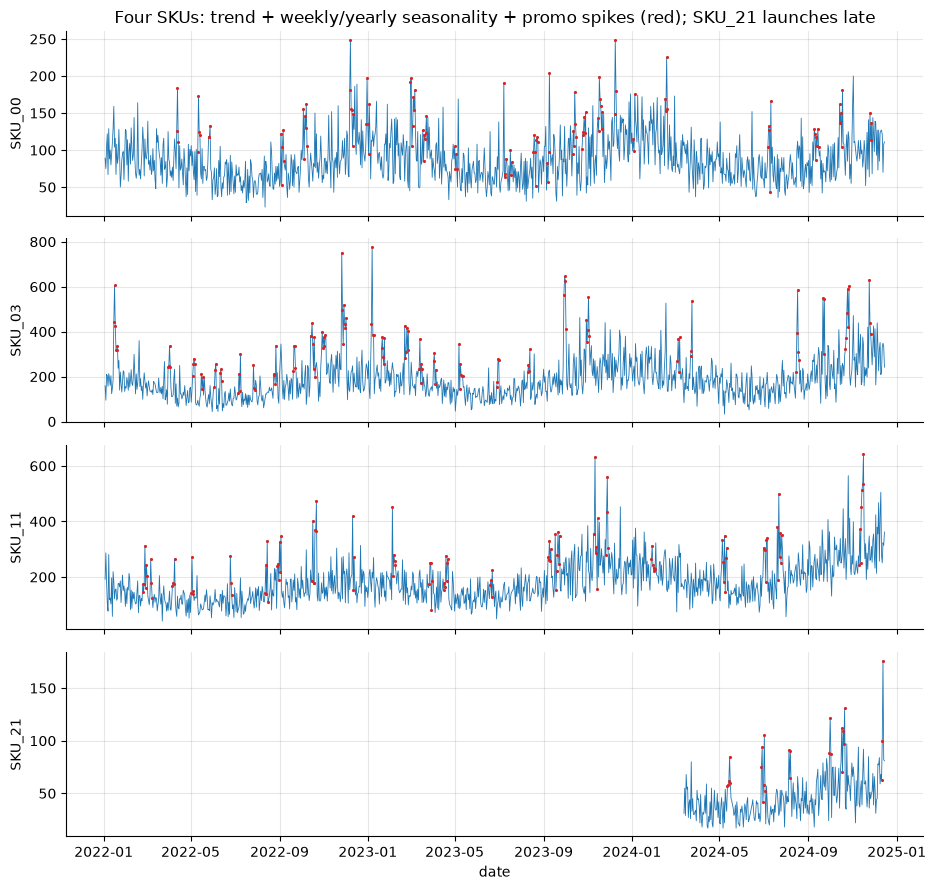

In [3]:
show = ["SKU_00", "SKU_03", "SKU_11", "SKU_21"]
fig, axes = plt.subplots(4, 1, figsize=(9.5, 9), sharex=True)
for ax, s in zip(axes, show):
    d = panel[panel["sku"] == s]
    ax.plot(d["date"], d["y"], lw=0.6)
    on = d[d["promo"] == 1]
    ax.plot(on["date"], on["y"], ".", ms=2.5, color="tab:red")
    ax.set_ylabel(s)
axes[0].set_title("Four SKUs: trend + weekly/yearly seasonality + promo spikes (red); "
                  "SKU_21 launches late")
axes[-1].set_xlabel("date")
plt.show()

## 2. Forecasting as supervised learning

Classical models (ETS, ARIMA) *are* the feature engineering: level, trend and season are
baked into the recurrence. The ML reframing makes features explicit — each row becomes
an i.i.d.-looking training example `(features known before/at date t, target y_t)`:

| family | examples | information cutoff |
|---|---|---|
| **lags** | `y[t-1], y[t-7], y[t-14], y[t-28]` | strictly before `t` |
| **rolling stats** | mean/std of `y[t-7..t-1]`, `y[t-28..t-1]` | strictly before `t` |
| **calendar** | day-of-week, month, Fourier day-of-year | known forever in advance |
| **covariates** | promo flag on day `t` | known *if planned* (promos: yes; weather: only as a forecast) |

Two design rules that carry most of the value:

1. **Every history feature is computed on `y.shift(1)`** — the rolling window ends at
   `t-1`. This one line is the difference between a model and a leak (Section 3).
2. **Grouped by SKU.** Lags must never cross series boundaries — a bug that silently
   feeds SKU_07's Tuesday into SKU_08's Monday after a long-to-wide-to-long mangle.

The lag-7 feature is the seasonal-naive forecast *as a feature*: the model learns how to
blend "same day last week" with trend and promo context, which is exactly why it can
beat the baseline it embeds.

In [4]:
LAGS = (1, 7, 14, 28)
ROLLS = (7, 28)
HIST_COLS = [f"lag_{k}" for k in LAGS] + [f"rmean_{w}" for w in ROLLS] + ["rstd_7"]
CAL_COLS = ["dow", "month", "doy_sin", "doy_cos", "doy_sin2", "doy_cos2", "promo"]
FEATURES = HIST_COLS + CAL_COLS


def add_history_features(df):
    """Lag / rolling features using ONLY information available strictly before each date.

    The crucial detail: every rolling window is computed on y.shift(1), so the window
    ends at t-1. All shifts are per-SKU (grouped) so features never cross series.
    """
    out = df.sort_values(["sku", "date"], kind="stable").reset_index(drop=True)
    g = out.groupby("sku", sort=False)["y"]
    for k in LAGS:
        out[f"lag_{k}"] = g.shift(k)
    for w in ROLLS:
        out[f"rmean_{w}"] = out.groupby("sku", sort=False)["y"].transform(
            lambda s: s.shift(1).rolling(w).mean())
    out["rstd_7"] = out.groupby("sku", sort=False)["y"].transform(
        lambda s: s.shift(1).rolling(7).std())
    return out


def add_calendar_features(df):
    out = df.copy()
    out["dow"] = out["date"].dt.dayofweek
    out["month"] = out["date"].dt.month
    frac = out["date"].dt.dayofyear / 365.25
    out["doy_sin"] = np.sin(2 * np.pi * frac)
    out["doy_cos"] = np.cos(2 * np.pi * frac)
    out["doy_sin2"] = np.sin(4 * np.pi * frac)
    out["doy_cos2"] = np.cos(4 * np.pi * frac)
    return out


feat = add_calendar_features(add_history_features(panel))
model_frame = feat.dropna(subset=HIST_COLS).reset_index(drop=True)
print(f"supervised frame: {len(model_frame):,} rows "
      f"({len(feat) - len(model_frame)} warm-up rows dropped)")
model_frame[["sku", "date", "y", "lag_1", "lag_7", "rmean_7", "rmean_28", "promo"]].head(3)

supervised frame: 21,200 rows (672 warm-up rows dropped)


,sku,date,y,lag_1,lag_7,rmean_7,rmean_28,promo
0,SKU_00,2022-01-31,128.0,90.0,50.0,77.571,95.679,0
1,SKU_00,2022-02-01,126.0,128.0,64.0,88.714,97.071,0
2,SKU_00,2022-02-02,80.0,126.0,86.0,97.571,98.893,0


## 3. The leakage minefield: the off-by-one rolling feature

The single most common forecasting bug in industry: a rolling feature computed
**without shifting**, so the window *includes today* — the row's own target sits inside
the feature. Here is how it happens in real life: the honest feature set already exists,
someone adds "recent momentum / volatility" features (`rolling(3).mean()`,
`rolling(7).mean()`) in a new pipeline stage, and forgets the `.shift(1)` the original
author knew to apply. The vicious part: **a time-based train/test split does not catch
it**, because the leaky features are computed the same way on the test rows. Offline
accuracy looks phenomenal; the model is broken.

We demonstrate the full arc: (a) leaky features → inflated "held-out" accuracy, (b) what
the model actually learned (feature importance), (c) the collapse when the features are
computed the only way they *can* be at 6 a.m. on the forecast date — from data through
yesterday.

In [5]:
leaky = model_frame.copy()
for w in (3, 7):                               # BUG: windows end at t, include today's y
    leaky[f"rmean_{w}_leaky"] = leaky.groupby("sku", sort=False)["y"].transform(
        lambda s: s.rolling(w).mean())
FEAT_LEAKY = FEATURES + ["rmean_3_leaky", "rmean_7_leaky"]

TEST_DAYS = 120
cutoff = panel["date"].max() - pd.Timedelta(days=TEST_DAYS)
tr, te = model_frame["date"] <= cutoff, model_frame["date"] > cutoff

m_correct = LGBMRegressor(**LGB_PARAMS).fit(model_frame.loc[tr, FEATURES],
                                            model_frame.loc[tr, "y"])
m_leaky = LGBMRegressor(**LGB_PARAMS).fit(leaky.loc[tr, FEAT_LEAKY], leaky.loc[tr, "y"])

mae_correct = np.mean(np.abs(model_frame.loc[te, "y"]
                             - m_correct.predict(model_frame.loc[te, FEATURES])))
mae_leaky_eval = np.mean(np.abs(leaky.loc[te, "y"]
                                - m_leaky.predict(leaky.loc[te, FEAT_LEAKY])))

# deployment reality: today's sales don't exist yet, so the pipeline can only feed the
# model windows ending *yesterday* — i.e. the honest versions of the same features
deploy = leaky.loc[te].copy()
deploy["rmean_7_leaky"] = deploy["rmean_7"]
deploy["rmean_3_leaky"] = leaky.groupby("sku", sort=False)["y"].transform(
    lambda s: s.shift(1).rolling(3).mean()).loc[te]
mae_leaky_deploy = np.mean(np.abs(deploy["y"] - m_leaky.predict(deploy[FEAT_LEAKY])))

print(f"correct model, honest eval        MAE = {mae_correct:7.2f}")
print(f"leaky model, leaky eval           MAE = {mae_leaky_eval:7.2f}   "
      f"<- looks {100 * (mae_correct - mae_leaky_eval) / mae_correct:.0f}% better; "
      f"this is the number that gets presented")
print(f"leaky model, deployed for real    MAE = {mae_leaky_deploy:7.2f}   "
      f"<- the number production sees")

correct model, honest eval        MAE =   32.88
leaky model, leaky eval           MAE =   15.80   <- looks 52% better; this is the number that gets presented
leaky model, deployed for real    MAE =   34.82   <- the number production sees


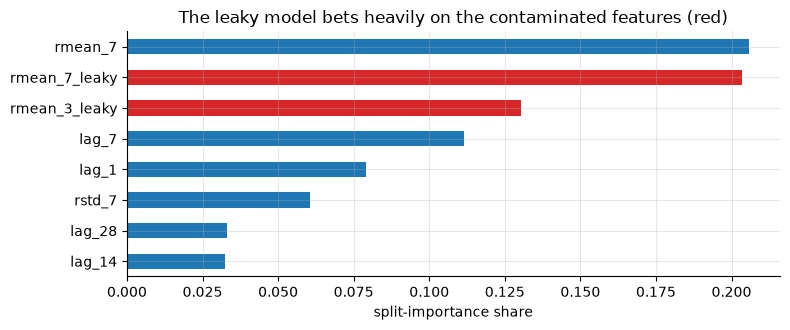

In [6]:
imp = (pd.Series(m_leaky.feature_importances_ / m_leaky.feature_importances_.sum(),
                 index=FEAT_LEAKY).sort_values(ascending=False).head(8))
colors = ["tab:red" if f.endswith("_leaky") else "tab:blue" for f in imp.index]
ax = imp.plot.barh(figsize=(8, 3.4), color=colors)
ax.invert_yaxis()
ax.set_title("The leaky model bets heavily on the contaminated features (red)")
ax.set_xlabel("split-importance share")
plt.show()

The leak roughly **halved the apparent error**, *survived a time-based holdout*, and the
deployed model is **worse than the correct one** — it learned to lean on features whose
informative part (today's sales) doesn't exist at prediction time.

**The senior discipline** is a question asked of every feature: *"can I compute this at
the moment the forecast job runs, using only data that will have arrived?"* Concretely:

- **shift before you roll** — windows end at `t-1` (or at `t-L` if your sales data
  lands with an L-day reporting lag; the shift must match the *pipeline* latency, not
  the theoretical one);
- **future covariates only if truly known**: promo calendars and prices are planned →
  usable; weather and competitor prices are only available as *forecasts* → train on
  the forecast, not the actual, or you leak;
- **any fitted transform** (scaler, target encoder, per-SKU normalization) must be fit
  on the training window only;
- and the meta-alarm: **if you beat seasonal naive by 3× on daily retail data, you have
  a leak, not a breakthrough**.

## 4. Multi-step forecasting: recursive vs direct

The supervised frame predicts *one step ahead*. Real jobs need a horizon (here H=28
days). Two standard strategies:

- **Recursive**: train one h=1 model; forecast day 1, append the prediction to history,
  recompute lags/rollings, forecast day 2, ... Pros: one model, coherent trajectories,
  uses the freshest lags. Cons: **feeds its own errors back into the features**, so
  errors can compound with horizon; also a train/serve mismatch (trained on true lags,
  served on predicted ones).
- **Direct**: train a separate model per horizon h — features frozen at the origin,
  target `y[t+h]`, calendar/promo taken from the *target* date. Pros: no error
  feedback; each model optimizes its own horizon. Cons: H models to train and version;
  forecasts across h come from different models, so trajectories can be jagged
  (non-coherent); long-h models ignore recent short-term signal.

(A pragmatic third option — one direct model with *horizon as a feature* trained on all
h at once — is Exercise 2.)

In [7]:
def recursive_forecast(predict_fn, history, future_cov):
    """Iterate one-step predictions over the horizon, re-deriving features each step.

    history:    long df [sku, date, promo, y] through the forecast origin.
    future_cov: long df [sku, date, promo] for the horizon (y unknown).
    predict_fn: maps a feature-row DataFrame (incl. 'sku' and FEATURES) -> array.
    """
    hist = history[["sku", "date", "promo", "y"]].copy()
    preds = []
    for day in sorted(future_cov["date"].unique()):
        step = future_cov.loc[future_cov["date"] == day,
                              ["sku", "date", "promo"]].copy()
        tail = hist.groupby("sku", sort=False).tail(35)     # enough for lag_28 / rmean_28
        block = pd.concat([tail, step.assign(y=np.nan)], ignore_index=True)
        rows = add_calendar_features(add_history_features(block))
        rows = rows[rows["date"] == day]
        step["y"] = np.clip(predict_fn(rows), 0, None)
        hist = pd.concat([hist, step], ignore_index=True)
        preds.append(step)
    return pd.concat(preds, ignore_index=True).rename(columns={"y": "yhat"})


def fit_direct_models(train_feat, horizons, params=LGB_PARAMS):
    """One LightGBM per horizon h: history features from origin t, target y[t+h-1] in the
    h=1 frame's terms, calendar/promo re-aligned to the target date."""
    models = {}
    for h in horizons:
        d = train_feat.copy()
        g = d.groupby("sku", sort=False)
        d["y_target"] = g["y"].shift(-(h - 1))
        for c in CAL_COLS:                                   # covariates of the target date
            d[c] = g[c].shift(-(h - 1))
        d = d.dropna(subset=HIST_COLS + CAL_COLS + ["y_target"])
        models[h] = LGBMRegressor(**params).fit(d[FEATURES], d["y_target"])
    return models


def direct_forecast(models, history, future_cov):
    """Anchor history features one day after the origin (all lags are actuals), then swap
    in each target date's calendar/promo and apply that horizon's model."""
    days = sorted(future_cov["date"].unique())
    tail = history.groupby("sku", sort=False).tail(35)
    step1 = future_cov.loc[future_cov["date"] == days[0],
                           ["sku", "date", "promo"]].assign(y=np.nan)
    block = add_calendar_features(add_history_features(
        pd.concat([tail[["sku", "date", "promo", "y"]], step1], ignore_index=True)))
    anchor = block.loc[block["date"] == days[0], ["sku"] + HIST_COLS]
    fut = add_calendar_features(future_cov[["sku", "date", "promo"]].copy())
    preds = []
    for h, day in enumerate(days, start=1):
        rows = fut[fut["date"] == day].merge(anchor, on="sku")
        rows["yhat"] = np.clip(models[h].predict(rows[FEATURES]), 0, None)
        preds.append(rows[["sku", "date", "yhat"]])
    return pd.concat(preds, ignore_index=True)

In [8]:
origin = panel["date"].max() - pd.Timedelta(days=H)
train_panel = panel[panel["date"] <= origin]
test_panel = panel[panel["date"] > origin]
future_cov = test_panel[["sku", "date", "promo"]]

train_feat = add_calendar_features(add_history_features(train_panel))
train_fit = train_feat.dropna(subset=HIST_COLS)

m_step1 = LGBMRegressor(**LGB_PARAMS).fit(train_fit[FEATURES], train_fit["y"])
rec = recursive_forecast(lambda r: m_step1.predict(r[FEATURES]), train_panel, future_cov)

direct_models = fit_direct_models(train_fit, range(1, H + 1))
dirf = direct_forecast(direct_models, train_panel, future_cov)
print(f"trained 1 recursive model + {H} direct models on {len(train_fit):,} rows")

trained 1 recursive model + 28 direct models on 20,528 rows


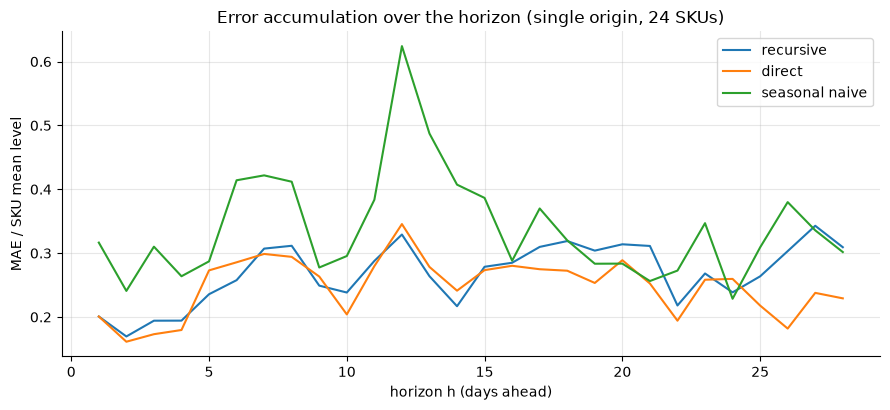

                h 1-7  h 22-28  late/early ratio
recursive       0.223    0.278             1.247
direct          0.225    0.226             1.004
seasonal naive  0.322    0.311             0.965


In [9]:
def snaive_forecast(history, future_cov):
    """Repeat each SKU's last 7 observed days across the horizon."""
    preds = []
    for s, grp in history.groupby("sku", sort=False):
        last7 = grp.sort_values("date")["y"].to_numpy()[-7:]
        days = sorted(future_cov.loc[future_cov["sku"] == s, "date"].unique())
        preds.append(pd.DataFrame({
            "sku": s, "date": days,
            "yhat": np.tile(last7, len(days) // 7 + 1)[:len(days)]}))
    return pd.concat(preds, ignore_index=True)


actual = test_panel[["sku", "date", "y"]]
byh = {}
for name, fc in [("recursive", rec), ("direct", dirf),
                 ("seasonal naive", snaive_forecast(train_panel, future_cov))]:
    m = fc.merge(actual, on=["sku", "date"])
    m["h"] = (m["date"] - origin).dt.days
    m["ae_rel"] = np.abs(m["y"] - m["yhat"]) / m.groupby("sku")["y"].transform("mean")
    byh[name] = m.groupby("h")["ae_rel"].mean()

byh = pd.DataFrame(byh)
ax = byh.plot(lw=1.5)
ax.set_title("Error accumulation over the horizon (single origin, 24 SKUs)")
ax.set_xlabel("horizon h (days ahead)")
ax.set_ylabel("MAE / SKU mean level")
plt.show()
print(pd.DataFrame({"h 1-7": byh.loc[1:7].mean(),
                    "h 22-28": byh.loc[22:28].mean(),
                    "late/early ratio": byh.loc[22:28].mean() / byh.loc[1:7].mean()}
                   ).round(3))

Typical picture: at short horizons the two are near-identical (recursive even has a
slight edge — freshest lags, one model). As h grows, **recursive drifts upward faster**:
every predicted day contaminates the lag features of the next, so a bias early in the
horizon compounds. Direct stays flatter because each horizon's model never sees a
prediction as input. Both beat seasonal naive at every horizon here — the promo
covariate and yearly features do a lot of that work.

Practical guidance: recursive for short horizons or when you need coherent sample
paths; direct (or horizon-as-feature) when long-horizon accuracy is what's paid for.
Hybrids ("rectify": direct models correcting a recursive base) exist but are rarely
worth the complexity in a first system.

## 5. Rolling-origin backtesting: ML vs seasonal naive vs ETS

One origin is an anecdote. The honest protocol is **rolling-origin backtesting**: pick
several forecast origins, train each method only on data through the origin, forecast
the next H days, score against actuals, aggregate. This mirrors production (models are
retrained and re-scored every cycle) and gives error bars across origins.

Scoring: **MASE with weekly scaling** — MAE divided by the in-sample MAE of the
seasonal-naive one-step forecast (|y_t − y_{t−7}|). Scale-free, so a 400-unit SKU and a
10-unit SKU contribute comparably, and MASE < 1 means "beats seasonal naive applied
in-sample". We also report the **share of (SKU, origin) slices where each method beats
seasonal naive** — a distributional claim, more robust than a mean.

In [10]:
def mase_scale(y, m=7):
    y = np.asarray(y, dtype=float)
    return np.mean(np.abs(y[m:] - y[:-m]))


def ets_forecast(history, future_cov, horizon=H):
    """Damped additive-trend, additive weekly-seasonal ETS per SKU."""
    preds = []
    for s, grp in history.groupby("sku", sort=False):
        ts = grp.set_index("date")["y"].asfreq("D")
        fit = ExponentialSmoothing(
            ts, trend="add", damped_trend=True, seasonal="add",
            seasonal_periods=7, initialization_method="estimated").fit()
        fc = fit.forecast(horizon)
        preds.append(pd.DataFrame({"sku": s, "date": fc.index,
                                   "yhat": np.clip(fc.to_numpy(), 0, None)}))
    return pd.concat(preds, ignore_index=True)


def rolling_origin_backtest(data, origins, horizon=H):
    """Retrain every method at each origin; return per-(method, origin, sku) scores."""
    rows = []
    for origin in origins:
        train = data[data["date"] <= origin]
        fut = data[(data["date"] > origin)
                   & (data["date"] <= origin + pd.Timedelta(days=horizon))]
        cov, actual = fut[["sku", "date", "promo"]], fut[["sku", "date", "y"]]

        tf = add_calendar_features(add_history_features(train)).dropna(subset=HIST_COLS)
        m1 = LGBMRegressor(**LGB_PARAMS).fit(tf[FEATURES], tf["y"])
        methods = {
            "seasonal naive": snaive_forecast(train, cov),
            "ETS (weekly)": ets_forecast(train, cov, horizon),
            "LightGBM global (recursive)": recursive_forecast(
                lambda r: m1.predict(r[FEATURES]), train, cov),
        }
        scales = train.groupby("sku")["y"].apply(mase_scale)
        for name, fc in methods.items():
            m = fc.merge(actual, on=["sku", "date"])
            per_sku = m.groupby("sku").apply(
                lambda g: np.mean(np.abs(g["y"] - g["yhat"])), include_groups=False)
            for s, mae in per_sku.items():
                rows.append({"origin": origin, "sku": s, "method": name,
                             "mae": mae, "mase": mae / scales[s]})
    return pd.DataFrame(rows)


origins = [panel["date"].max() - pd.Timedelta(days=d) for d in (3 * H, 2 * H, H)]
bt = rolling_origin_backtest(panel, origins)

summary = (bt.pivot_table(index="method", values="mase", aggfunc=["mean", "median"])
             .droplevel(1, axis=1))
summary.columns = ["MASE mean", "MASE median"]
wide = bt.pivot_table(index=["origin", "sku"], columns="method", values="mase")
summary["% slices beating snaive"] = [
    100 * (wide[m] < wide["seasonal naive"]).mean() if m != "seasonal naive" else np.nan
    for m in summary.index]
summary.sort_values("MASE mean")

,MASE mean,MASE median,% slices beating snaive
method,,,
LightGBM global (recursive),0.956,0.936,91.667
ETS (weekly),1.047,1.008,88.889
seasonal naive,1.285,1.231,NaN


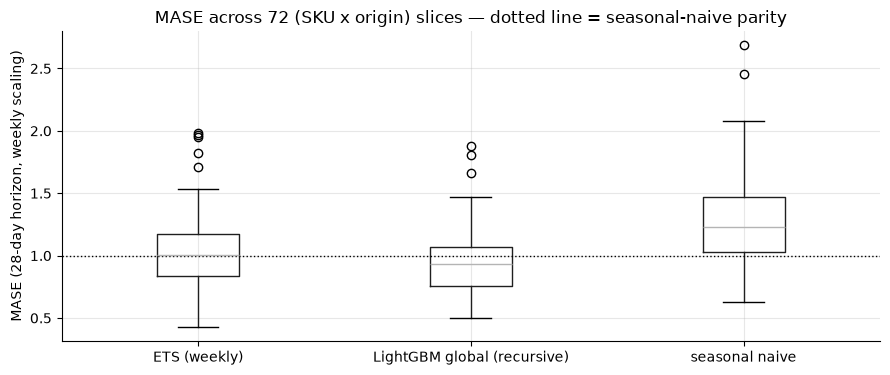

In [11]:
ax = bt.boxplot(column="mase", by="method", grid=True, figsize=(9, 4))
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set_title("MASE across 72 (SKU x origin) slices — dotted line = seasonal-naive parity")
ax.set_ylabel("MASE (28-day horizon, weekly scaling)")
plt.suptitle("")
ax.set_xlabel("")
plt.show()

**Regime 1 verdict**: the global LightGBM wins at every origin, and wins *because of
structure the classical models cannot see* — the promo calendar (ETS treats promo
spikes as noise, and worse, smears recent promo lift into its level and seasonal
state), the yearly seasonality (weekly-only ETS misses the October–December ramp the
later origins forecast into; TBATS-style multi-seasonal models exist but are slow at
scale), and ~21,000 rows of cross-SKU training signal.

Now the other regime, which interviewers love because candidates who have only read M5
hype get it wrong: **a single short, clean univariate series**.

### 5b. Where ML loses: short, clean, univariate — and trees can't extrapolate

Monthly series, n=60 (five years), smooth trend + stable seasonality, no covariates.
This is ETS's home turf. It is also a structural failure mode for tree ensembles:
**a tree's prediction is a piecewise-constant function of the features — it cannot
output a value outside the range of training targets**. With a persistent upward trend,
a recursive tree forecast plateaus at roughly the historical maximum.

                      MASE (h=1..12)
ETS                            0.191
LightGBM (recursive)           0.932
seasonal naive                 1.400


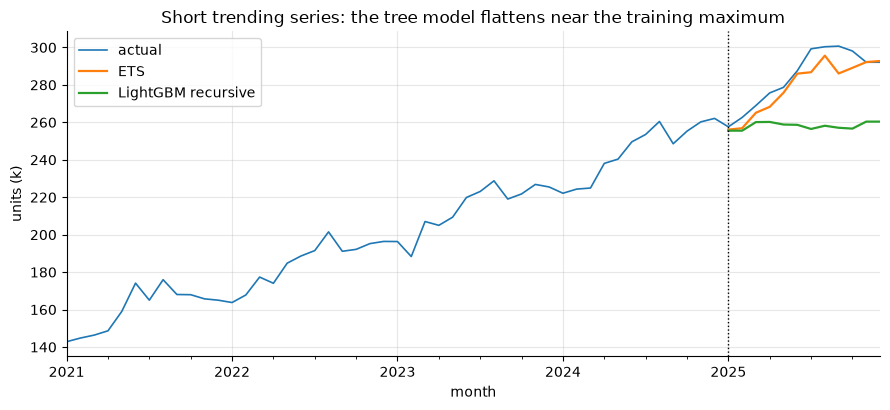

In [12]:
n_m = 60
mdates = pd.date_range("2021-01-01", periods=n_m, freq="MS")
seas_m = np.array([-8, -10, -3, 0, 3, 6, 10, 9, 2, -1, -4, -4], dtype=float)
tm = np.arange(n_m)
y_m = 150 * 1.012 ** tm + seas_m[tm % 12] + rng.normal(0, 3.5, n_m)
short = pd.Series(y_m, index=mdates, name="units_k")

h_m, cut = 12, n_m - 12
tr_m, te_m = short.iloc[:cut], short.iloc[cut:]

ets_m = ExponentialSmoothing(tr_m, trend="add", damped_trend=True, seasonal="add",
                             seasonal_periods=12,
                             initialization_method="estimated").fit()
fc_ets = ets_m.forecast(h_m)

sup = pd.DataFrame({"y": short})
for k in (1, 2, 12):
    sup[f"lag_{k}"] = short.shift(k)
sup["month"] = sup.index.month
sup_tr = sup.iloc[:cut].dropna()
FEATS_M = ["lag_1", "lag_2", "lag_12", "month"]
m_short = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15,
                        min_child_samples=5, random_state=42, verbose=-1
                        ).fit(sup_tr[FEATS_M], sup_tr["y"])

hist_vals = short.iloc[:cut].to_list()
fc_gbm = []
for step in range(h_m):
    row = pd.DataFrame({"lag_1": [hist_vals[-1]], "lag_2": [hist_vals[-2]],
                        "lag_12": [hist_vals[-12]], "month": [te_m.index[step].month]})
    yhat = float(m_short.predict(row[FEATS_M])[0])
    fc_gbm.append(yhat)
    hist_vals.append(yhat)
fc_gbm = pd.Series(fc_gbm, index=te_m.index)

scale_m = mase_scale(tr_m.to_numpy(), m=12)
snaive_m = pd.Series(tr_m.to_numpy()[-12:], index=te_m.index)
res_m = pd.DataFrame({
    "MASE (h=1..12)": {
        "seasonal naive": np.mean(np.abs(te_m - snaive_m)) / scale_m,
        "ETS": np.mean(np.abs(te_m - fc_ets)) / scale_m,
        "LightGBM (recursive)": np.mean(np.abs(te_m - fc_gbm)) / scale_m,
    }}).sort_values("MASE (h=1..12)")
print(res_m.round(3))

ax = short.plot(lw=1.2, label="actual")
fc_ets.plot(ax=ax, lw=1.6, label="ETS")
fc_gbm.plot(ax=ax, lw=1.6, label="LightGBM recursive")
ax.axvline(te_m.index[0], color="k", ls=":", lw=1)
ax.set_title("Short trending series: the tree model flattens near the training maximum")
ax.set_ylabel("units (k)")
ax.set_xlabel("month")
ax.legend()
plt.show()

ETS wins decisively, and the plot shows *why*, not just *that*: the LightGBM forecast
goes flat while the series keeps climbing — piecewise-constant leaves cannot
extrapolate, and 47 usable training rows cannot support 300 trees learning anything
subtle. Mitigations exist (forecast the *difference* or ratio `y_t − y_{t−12}`, add a
linear-model blend, detrend first) and are worth mentioning in an interview — but the
honest senior answer is: **with one short clean series, use ETS/ARIMA; ML forecasting
earns its complexity when there are many related series and informative covariates.**
The M-competitions found exactly this: pure ML lost (M3 era, single series) until M4/M5
provided huge panels of related series, where global gradient-boosting won.

## 6. Global vs per-SKU models

With 24 series you could train 24 separate models. Should you? The global model's case:

- **Sample efficiency**: weekly shape, promo response, and holiday lift are *shared*
  structure. One model pools ~25k rows to learn them; each per-SKU model gets ~1k.
- **Cold start**: a SKU with 7 months of history has never seen December. The global
  model has — it transfers the yearly shape from older SKUs the moment the new SKU's
  lag features carry its level.
- **Operations**: one artifact to train, tune, monitor, and roll back — vs 10,000.

The per-SKU case: idiosyncratic dynamics that pooling would average away, no risk of
one segment dominating training. In practice the hybrid — a global model with SKU/
category identifiers as categorical features (plus per-series normalization fit on the
training window only) — captures most of both.

In [13]:
per_sku_models = {}
small = dict(LGB_PARAMS, n_estimators=200, num_leaves=31)
for s, grp in train_fit.groupby("sku", sort=False):
    per_sku_models[s] = LGBMRegressor(**small).fit(grp[FEATURES], grp["y"])


def per_sku_predict(rows):
    out = np.empty(len(rows))
    for s, grp in rows.groupby("sku", sort=False):
        out[np.flatnonzero((rows["sku"] == s).to_numpy())] = \
            per_sku_models[s].predict(grp[FEATURES])
    return out


rec_local = recursive_forecast(per_sku_predict, train_panel, future_cov)

scales_final = train_panel.groupby("sku")["y"].apply(mase_scale)
comp = []
for name, fc in [("global", rec), ("per-SKU", rec_local)]:
    m = fc.merge(actual, on=["sku", "date"])
    per = m.groupby("sku").apply(
        lambda g: np.mean(np.abs(g["y"] - g["yhat"])), include_groups=False) / scales_final
    comp.append(per.rename(name))
comp = pd.concat(comp, axis=1)
comp["cohort"] = np.where(comp.index.isin(LATE_SKUS), "late launch (~7 mo)",
                          "established (~3 yr)")
comp.groupby("cohort")[["global", "per-SKU"]].mean().round(3)

,global,per-SKU
cohort,,
established (~3 yr),1.033,0.972
late launch (~7 mo),1.079,1.194


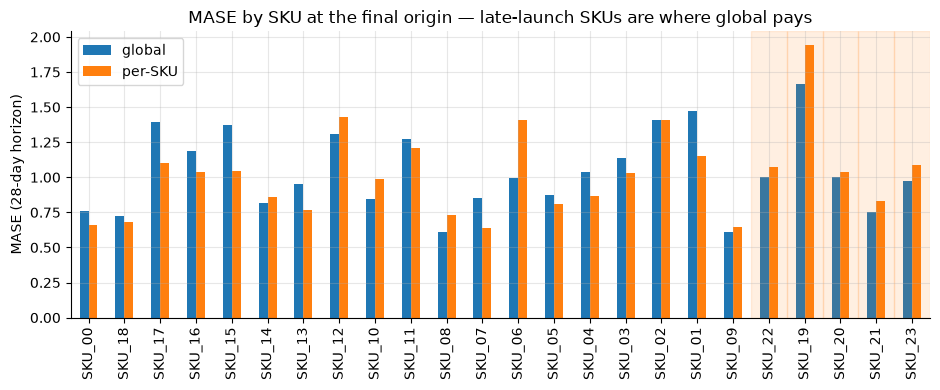

In [14]:
ax = comp.sort_values("cohort").plot.bar(y=["global", "per-SKU"], figsize=(9.5, 4))
ax.set_title("MASE by SKU at the final origin — late-launch SKUs are where global pays")
ax.set_ylabel("MASE (28-day horizon)")
ax.set_xlabel("")
for i, s in enumerate(comp.sort_values("cohort").index):
    if s in LATE_SKUS:
        ax.axvspan(i - 0.5, i + 0.5, color="tab:orange", alpha=0.12)
plt.show()

Read the table honestly: on **established SKUs the per-SKU models are competitive —
even slightly ahead** here. With ~3 years of history each, a local model can afford to
learn its own weekly shape, and pooling buys little. The story flips on the
**late-launch cohort, where the global model is clearly better**: those local models
have ~8 months of usable rows, have seen only a handful of promos, and — decisive here
— have **never seen a holiday season**, while the forecast horizon runs into
mid-December. The global model transfers the yearly ramp it learned from two Decembers
of other SKUs' history. This gap *widens* in reality, where new SKUs launch weekly and
the catalog has a long tail of sparse sellers — which is why production systems default
to global models even though mature, data-rich series may individually do fine locally.

**Hierarchical reconciliation (concept).** Forecasts live in a hierarchy — SKU →
category → region → total — and independently produced forecasts won't add up:
the sum of SKU forecasts ≠ the total forecast, which planning teams will not accept.
Options: **bottom-up** (sum SKU forecasts; unbiased aggregation but noisy), **top-down**
(forecast the stable total, split by historical proportions; loses SKU signal),
and **optimal/MinT reconciliation** — forecast *every* level, then project the stacked
forecasts onto the coherent subspace, weighting by forecast-error covariance. MinT
typically improves accuracy at *all* levels, not just coherence. Know the vocabulary;
implementing MinT is out of scope here (see `hierarchicalforecast` / Hyndman FPP3 ch. 11).

## 7. Probabilistic forecasts: quantile regression, pinball loss, coverage

Point forecasts answer "what do we expect?". Inventory, staffing, and cash decisions
need "how bad could it plausibly get?" — a **quantile**. The newsvendor logic (notebook
04 in `../09_finance_and_operations/`) makes it precise: with underage cost $c_u$
(lost margin) and overage cost $c_o$ (holding/markdown), the optimal stocking point is
the demand quantile at the **critical fractile** $c_u/(c_u+c_o)$ — often P80–P95, never
the mean. A point forecast, however accurate, cannot answer that question.

LightGBM fits quantiles directly: `objective="quantile", alpha=q` minimizes **pinball
loss** $L_q(y,\hat y) = \max\big(q\,(y-\hat y),\,(q-1)(y-\hat y)\big)$, whose minimizer
is the conditional q-quantile (at q=0.5 it is MAE/2 — the median). We train P10/P50/P90
models and — the step most teams skip — **check empirical coverage**: the fraction of
actuals inside [P10, P90] should be ≈ 80%. Uncalibrated intervals silently corrupt
every safety-stock computation downstream.

We evaluate one-step-ahead over the last 90 days (features from actuals, so each
prediction is an honest h=1 forecast; multi-step quantiles come back in the Pitfalls).

In [15]:
Q_LEVELS = (0.1, 0.5, 0.9)
q_cut = panel["date"].max() - pd.Timedelta(days=90)
q_tr = model_frame[model_frame["date"] <= q_cut]
q_te = model_frame[model_frame["date"] > q_cut].copy()

q_models = {}
for a in Q_LEVELS:
    q_models[a] = LGBMRegressor(objective="quantile", alpha=a, **LGB_PARAMS
                                ).fit(q_tr[FEATURES], q_tr["y"])

q_pred = np.column_stack([q_models[a].predict(q_te[FEATURES]) for a in Q_LEVELS])
crossed = np.mean(np.diff(q_pred, axis=1) < 0)
q_pred = np.sort(q_pred, axis=1)          # enforce monotone quantiles
q_te[["p10", "p50", "p90"]] = np.clip(q_pred, 0, None)


def pinball(y, yhat, q):
    d = y - yhat
    return np.mean(np.maximum(q * d, (q - 1) * d))


print(f"quantile crossings before sorting: {crossed:.2%} of rows")
for a, col in zip(Q_LEVELS, ["p10", "p50", "p90"]):
    print(f"pinball loss @ q={a:.1f}: {pinball(q_te['y'], q_te[col], a):6.2f}")
cover = ((q_te["y"] >= q_te["p10"]) & (q_te["y"] <= q_te["p90"])).mean()
print(f"\nempirical coverage of [P10, P90]: {cover:.1%}  (nominal 80%)")
per_sku_cov = q_te.groupby("sku").apply(
    lambda g: ((g["y"] >= g["p10"]) & (g["y"] <= g["p90"])).mean(),
    include_groups=False)
print(f"per-SKU coverage: min {per_sku_cov.min():.0%}, "
      f"median {per_sku_cov.median():.0%}, max {per_sku_cov.max():.0%}")

quantile crossings before sorting: 0.02% of rows
pinball loss @ q=0.1:   6.31
pinball loss @ q=0.5:  17.19
pinball loss @ q=0.9:  10.88

empirical coverage of [P10, P90]: 71.2%  (nominal 80%)
per-SKU coverage: min 30%, median 73%, max 82%


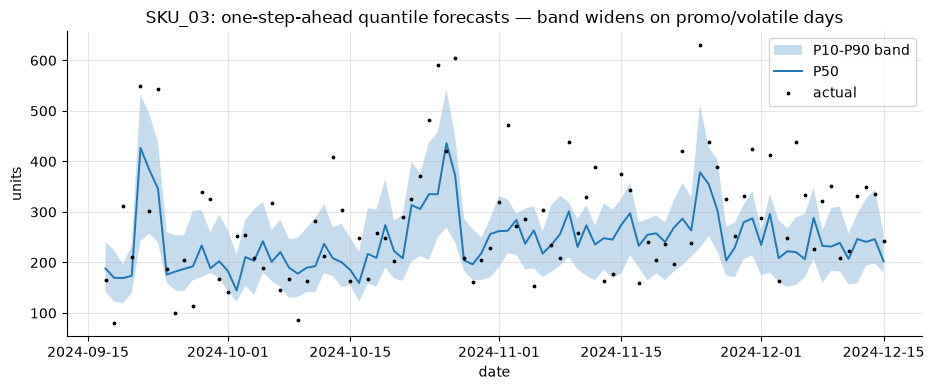

In [16]:
s = "SKU_03"
d = q_te[q_te["sku"] == s]
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.fill_between(d["date"], d["p10"], d["p90"], alpha=0.25, label="P10-P90 band")
ax.plot(d["date"], d["p50"], lw=1.4, label="P50")
ax.plot(d["date"], d["y"], "k.", ms=3.5, label="actual")
ax.set_title(f"{s}: one-step-ahead quantile forecasts — band widens on promo/volatile days")
ax.set_ylabel("units")
ax.set_xlabel("date")
ax.legend()
plt.show()

Two findings, both typical of real systems. First, the raw band **under-covers**:
quantile regression gives calibrated quantiles only if the model is well specified and
the eval window looks like training — here the final 90 days run into the holiday ramp,
levels the model has partly never seen, and the band is too narrow for it. Second, the
**per-SKU spread**: some SKUs sit near nominal, others far below — an aggregate check
can hide badly calibrated segments. Never ship intervals without a coverage check.
Fixes, in increasing rigor: widen via a validation multiplier, **conformalized quantile
regression** (Exercise 3 implements the split-conformal adjustment and recovers ~80%),
or a parametric head (e.g., negative binomial) when counts are small.
Note the band is *heteroscedastic* — wider on promo days and volatile SKUs — which is
exactly what a constant "±z·σ" band around a point forecast cannot give you, and what
makes per-SKU safety stock differ from a blanket service-level rule.

## 8. Pitfalls

The two big ones — the unshifted rolling window (Section 3) and judging ML on a regime
where it structurally loses (Section 5b) — got their own sections. Three more that
recur in practice, two demonstrated below:

1. **Random K-fold CV on time-series rows.** Shuffled folds put `y_t` in training while
   `y_{t+1}` (whose `lag_1` *is* `y_t`) sits in validation — the model interpolates
   neighbors instead of extrapolating the future, and CV overstates skill.
2. **Recursive feedback of a quantile model.** Feeding P90 predictions back into lag
   features does not produce "the P90 path": each step conditions on an already-extreme
   history, so the trajectory drifts far above the median path — and **quantiles are
   not additive**, so summing per-day P90s wildly overstates the horizon-total P90 that
   safety stock actually needs. Multi-step quantiles need direct per-horizon models or
   simulated sample paths.
3. **Covariates that won't exist at prediction time.** Training on *actual* weather,
   competitor prices, or realized promo uplift, then serving with forecasts/plans of
   them. Train with what serving will see — including your data pipeline's reporting
   lag (if sales land T+2, your freshest usable lag is `lag_2`, not `lag_1`).

In [17]:
# Pitfall 1: shuffled K-fold vs honest forward evaluation (same model, same features)
kf_maes = []
X_all, y_all = model_frame[FEATURES], model_frame["y"]
for tr_ix, te_ix in KFold(n_splits=3, shuffle=True, random_state=42).split(X_all):
    m = LGBMRegressor(**dict(LGB_PARAMS, n_estimators=200))
    m.fit(X_all.iloc[tr_ix], y_all.iloc[tr_ix])
    kf_maes.append(np.mean(np.abs(y_all.iloc[te_ix] - m.predict(X_all.iloc[te_ix]))))

print(f"random 3-fold CV MAE estimate : {np.mean(kf_maes):.2f}")
print(f"honest forward-split MAE      : {mae_correct:.2f}   (Section 3, same features)")
print(f"optimism from shuffling       : "
      f"{100 * (mae_correct - np.mean(kf_maes)) / mae_correct:.0f}% too rosy")

random 3-fold CV MAE estimate : 23.37
honest forward-split MAE      : 32.88   (Section 3, same features)
optimism from shuffling       : 29% too rosy


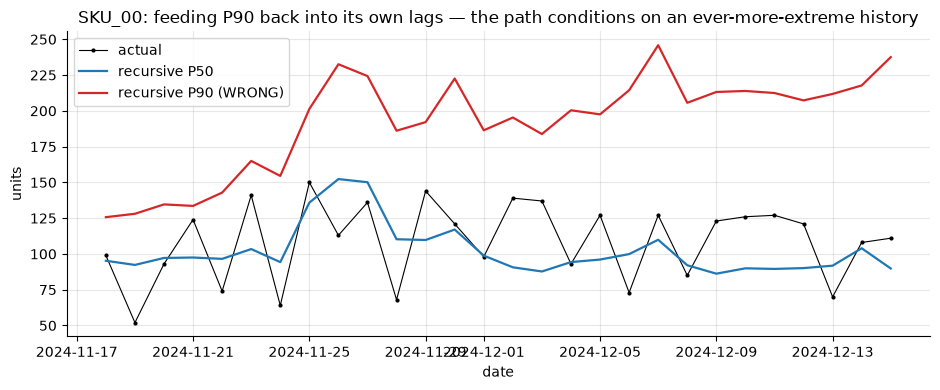

          share y <= 'P90'  'P90'/P50 ratio
h                                          
(0, 7]               0.875            1.421
(7, 14]              0.869            1.655
(14, 21]             0.887            1.886
(21, 28]             0.911            2.141

sum of daily 'P90' vs actual 28-day demand: +42.0% (covers 96% of SKUs)


In [18]:
# Pitfall 2: the "recursive P90" drifts away from the median path and doesn't sum
rec_p90 = recursive_forecast(lambda r: q_models[0.9].predict(r[FEATURES]),
                             train_panel, future_cov)
rec_p50 = recursive_forecast(lambda r: q_models[0.5].predict(r[FEATURES]),
                             train_panel, future_cov)
s = "SKU_00"
a = actual[actual["sku"] == s]
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(a["date"], a["y"], "k.-", lw=0.8, ms=4, label="actual")
for name, fc, c in [("recursive P50", rec_p50, "tab:blue"),
                    ("recursive P90 (WRONG)", rec_p90, "tab:red")]:
    f = fc[fc["sku"] == s]
    ax.plot(f["date"], f["yhat"], lw=1.6, color=c, label=name)
ax.set_title(f"{s}: feeding P90 back into its own lags — the path conditions on an "
             "ever-more-extreme history")
ax.set_ylabel("units")
ax.set_xlabel("date")
ax.legend()
plt.show()

diag = (rec_p90.merge(actual, on=["sku", "date"])
              .merge(rec_p50.rename(columns={"yhat": "p50"}), on=["sku", "date"]))
diag["h"] = (diag["date"] - origin).dt.days
buckets = diag.groupby(pd.cut(diag["h"], [0, 7, 14, 21, 28]), observed=True).apply(
    lambda g: pd.Series({"share y <= 'P90'": np.mean(g["y"] <= g["yhat"]),
                         "'P90'/P50 ratio": np.mean(g["yhat"] / g["p50"])}),
    include_groups=False)
print(buckets.round(3))
tot = diag.groupby("sku").agg(actual=("y", "sum"), p90_sum=("yhat", "sum"))
print(f"\nsum of daily 'P90' vs actual 28-day demand: "
      f"{tot['p90_sum'].sum() / tot['actual'].sum() - 1:+.1%} "
      f"(covers {np.mean(tot['actual'] <= tot['p90_sum']):.0%} of SKUs)")

The trap within the trap: the *pointwise* exceedance can look nearly calibrated,
because two errors offset — the median path under-forecasts the December ramp while
the recursion inflates the path. Don't be reassured. The implied band ('P90'/P50)
balloons with horizon instead of widening like a genuine predictive distribution, and
stocking the **sum of daily 'P90's** would buy far more than actual 28-day demand and
cover well above 90% of SKUs — a P90 service target silently turned into overstock.
For horizon-total quantiles: simulate sample paths (e.g., bootstrap one-step residuals
through the recursion, then take quantiles of the simulated totals) or fit a direct
quantile model on the h-day total.

## 9. Interview corner

**Q1. "Design a system to forecast daily demand for 10,000 SKUs."**
Strong answer outline: (i) *one global* LightGBM-family model (or a handful by data
regime: fast-movers vs intermittent), long-format feature pipeline — grouped lags,
shifted rollings, calendar, promo/price plans, SKU/category IDs as categoricals;
(ii) direct multi-horizon or horizon-as-feature training; (iii) rolling-origin backtest
harness as CI — every model change re-scored on MASE/pinball vs **seasonal-naive and
ETS gates**; (iv) quantile heads for inventory consumers; (v) weekly retrain, daily
score; monitoring on rolling MASE vs baseline, coverage drift, feature-pipeline lag;
(vi) cold start via the global model + category features; (vii) reconciliation
(bottom-up or MinT) so SKU forecasts sum to the planning totals. Mentioning "one model,
not 10,000" and "the baseline gate" is what marks the answer senior.

**Q2. "How do you prevent leakage in time-series features?"**
Shift before you roll (windows end at t−1 — or t−L under reporting lag L); every
feature must pass "computable at the moment the forecast job runs"; fitted transforms
(scalers, encoders, per-series normalization) fit on the training window only;
time-based splits with the *same information set as production* (backtest = replay of
the serving job); future covariates only if genuinely known (plans yes, actuals of
weather no). And the smell test: accuracy far beyond seasonal naive on noisy retail
data means a leak until proven otherwise.

**Q3. "When does the business need quantile forecasts rather than point forecasts?"**
Whenever the decision costs are asymmetric: safety stock / reorder points (newsvendor
critical fractile c_u/(c_u+c_o)), staffing floors, cash buffers, SLA commitments. Also
intermittent demand, where the mean is between 0 and 1 units and useless. Add that
quantiles must be *calibrated* (empirical coverage checks) and that the needed quantile
comes from the cost ratio, not from taste — P90 for high-margin items, closer to P50
for perishables with heavy markdown cost.

**Q4. "Recursive vs direct multi-step — trade-offs?"**
Recursive: one model, coherent path, freshest lags, but compounds its own errors and
has train/serve mismatch (trained on true lags, served on predictions). Direct: no
feedback, per-horizon optimization, but H models, non-coherent trajectories, and each
long-h model ignores what happened after the origin. Horizon-as-feature is the
pragmatic middle. Cite the error-vs-horizon curve as the empirical arbiter.

**Q5. "Global vs per-series models — when does each win?"**
Global wins with many related series, shared drivers (promos, holidays), long-tail and
cold-start SKUs — sample efficiency and one artifact to operate. Per-series wins with
few, long, idiosyncratic series (a company's total revenue; a country's load curve)
and when regulation/interpretability demands isolation. Hybrid: global model +
series-ID categoricals + per-series normalization (train-window stats only).

**Q6. "Your gradient-boosting model lost to seasonal naive in production. Diagnose."**
Ordered checklist: (i) leakage in backtest → the offline win was fake; (ii) trend the
trees can't extrapolate (check: are predictions capped at historical max? fix: model
differences or add trend feature/linear blend); (iii) regime change after training
cutoff (promo mix, assortment); (iv) feature pipeline drift — serving lags differ from
training lags; (v) it was never actually better: was the backtest rolling-origin with
enough origins, scored scale-free? The senior move is naming the *baseline gate*: no
model ships unless it beats snaive over rolling origins.

**Q7. "A new SKU launches next month. How do you forecast it?"**
No history → no lags: use the global model's cold-start path — category/attribute
features, launch-curve profiles from historical analog launches, priors from the
category's seasonality; switch on lag features as history accrues. Quantify the
extra uncertainty (wider quantiles) and plan inventory off the quantiles, not the point.

## 10. Key takeaways

- Forecasting-as-regression = grouped lags + **shifted** rolling stats + calendar +
  *plannable* covariates. The lag-7 feature embeds seasonal naive; the model's job is
  to beat the baseline it contains.
- The off-by-one rolling leak survives a time-based holdout and roughly halves the
  apparent error; the deployed model is *worse* than the honest one. Test every feature
  with "can I compute this when the job runs?"
- Recursive multi-step compounds its own errors with horizon; direct avoids feedback at
  the cost of H models and non-coherent paths. Compare them empirically per use case.
- Evaluation is **rolling-origin backtesting** with scale-free metrics (MASE) and a
  share-beating-baseline statistic — never a single split, never plain MAPE across SKUs.
- ML forecasting wins with **many related series + covariates** (global models, sample
  efficiency, cold start). On short clean univariate series ETS wins — and trees
  structurally cannot extrapolate trend.
- One global model beats 10,000 local models operationally and statistically on the
  long tail; hierarchical reconciliation (bottom-up / MinT) makes forecasts coherent
  across SKU → category → total.
- Decisions consume **quantiles**: pinball loss trains them, empirical coverage
  validates them, the newsvendor critical fractile picks which one to stock at.
- Never feed an extreme quantile recursively; multi-step uncertainty needs direct
  per-horizon quantile models or simulated paths.

**Cross-references**: baselines/ETS/SARIMA and metric pathologies —
`02_classical_forecasting` (this folder); leakage and evaluation hygiene in tabular ML —
`../04_ml_tabular/`; quantiles → inventory decisions — notebook 04 in
`../09_finance_and_operations/`.

## 11. Exercises

**Exercise 1.** Add a `lag_364` feature (last year, same day-of-week: 364 = 52×7) plus
a 91-day rolling mean to the feature set, refit the h=1 global model, and re-run the
final-origin recursive forecast. Does yearly memory at the *observation* level improve
on the Fourier calendar features? Report MASE before/after.

**Exercise 2.** Implement the **horizon-as-feature** direct strategy: stack training
frames for h ∈ {1, 7, 14, 21, 28} with `h` as a feature, train ONE model, and compare
MAE-by-horizon against the 28 per-horizon direct models from Section 4.

**Exercise 3.** **Conformalize** the P10–P90 band: on a 45-day calibration window
compute conformity scores s = max(P10 − y, y − P90), take the 80th percentile q̂, widen
the band by q̂ on the final 45 days, and verify coverage moves to ≈80%.

In [19]:
# --- Solution 1 ---
FEATURES_EX = FEATURES + ["lag_364", "rmean_91"]


def add_yearly_history(df):
    out = df.copy()
    out["lag_364"] = out.groupby("sku", sort=False)["y"].shift(364)
    out["rmean_91"] = out.groupby("sku", sort=False)["y"].transform(
        lambda s: s.shift(1).rolling(91).mean())
    return out


def add_all_ex1(df):
    return add_yearly_history(add_calendar_features(add_history_features(df)))


tf_ex = add_all_ex1(train_panel)
# late-launch SKUs have no lag_364 — keep them, let LightGBM route NaNs (its default)
fit_ex = tf_ex.dropna(subset=HIST_COLS)
m_ex1 = LGBMRegressor(**LGB_PARAMS).fit(fit_ex[FEATURES_EX], fit_ex["y"])


def recursive_ex1(history, cov):
    hist = history[["sku", "date", "promo", "y"]].copy()
    preds = []
    for day in sorted(cov["date"].unique()):
        step = cov.loc[cov["date"] == day, ["sku", "date", "promo"]].copy()
        tail = hist.groupby("sku", sort=False).tail(370)   # need 364 days back
        rows = add_all_ex1(pd.concat([tail, step.assign(y=np.nan)], ignore_index=True))
        rows = rows[rows["date"] == day]
        step["y"] = np.clip(m_ex1.predict(rows[FEATURES_EX]), 0, None)
        hist = pd.concat([hist, step], ignore_index=True)
        preds.append(step)
    return pd.concat(preds, ignore_index=True).rename(columns={"y": "yhat"})


rec_ex1 = recursive_ex1(train_panel, future_cov)
for name, fc in [("baseline features", rec), ("+ lag_364 & rmean_91", rec_ex1)]:
    m = fc.merge(actual, on=["sku", "date"])
    per = m.groupby("sku").apply(
        lambda g: np.mean(np.abs(g["y"] - g["yhat"])), include_groups=False) / scales_final
    print(f"{name:24s} mean MASE = {per.mean():.3f}")
print("Yearly features at observation level add little here: the Fourier terms already "
      "capture the smooth yearly shape, and lag_364 is one noisy count observation.")

baseline features        mean MASE = 1.043
+ lag_364 & rmean_91     mean MASE = 0.985
Yearly features at observation level add little here: the Fourier terms already capture the smooth yearly shape, and lag_364 is one noisy count observation.


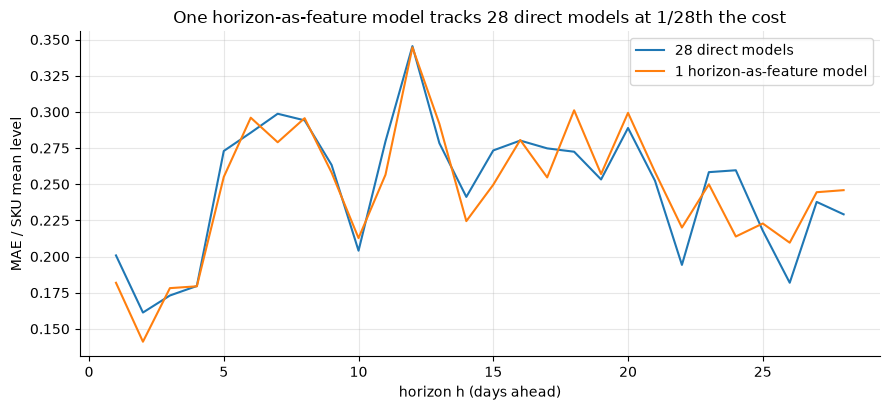

Note: it was trained on h in {1,7,14,21,28} yet predicts every h — the model interpolates across the horizon feature. This is the standard production compromise.


In [20]:
# --- Solution 2 ---
H_SET = (1, 7, 14, 21, 28)
stack = []
for h in H_SET:
    d = train_fit.copy()
    g = d.groupby("sku", sort=False)
    d["y_target"] = g["y"].shift(-(h - 1))
    for c in CAL_COLS:
        d[c] = g[c].shift(-(h - 1))
    d["h"] = h
    stack.append(d.dropna(subset=HIST_COLS + CAL_COLS + ["y_target"]))
stack = pd.concat(stack, ignore_index=True)
FEAT_H = FEATURES + ["h"]
m_haf = LGBMRegressor(**LGB_PARAMS).fit(stack[FEAT_H], stack["y_target"])

# predict at the final origin using the same anchor-and-swap mechanics as direct_forecast
days = sorted(future_cov["date"].unique())
tail = train_panel.groupby("sku", sort=False).tail(35)
step1 = future_cov.loc[future_cov["date"] == days[0],
                       ["sku", "date", "promo"]].assign(y=np.nan)
block = add_calendar_features(add_history_features(
    pd.concat([tail[["sku", "date", "promo", "y"]], step1], ignore_index=True)))
anchor = block.loc[block["date"] == days[0], ["sku"] + HIST_COLS]
fut = add_calendar_features(future_cov[["sku", "date", "promo"]].copy())
haf_preds = []
for h, day in enumerate(days, start=1):
    rows = fut[fut["date"] == day].merge(anchor, on="sku")
    rows["h"] = h
    rows["yhat"] = np.clip(m_haf.predict(rows[FEAT_H]), 0, None)
    haf_preds.append(rows[["sku", "date", "yhat"]])
haf = pd.concat(haf_preds, ignore_index=True)

cmp_h = {}
for name, fc in [("28 direct models", dirf), ("1 horizon-as-feature model", haf)]:
    m = fc.merge(actual, on=["sku", "date"])
    m["h"] = (m["date"] - origin).dt.days
    m["ae_rel"] = np.abs(m["y"] - m["yhat"]) / m.groupby("sku")["y"].transform("mean")
    cmp_h[name] = m.groupby("h")["ae_rel"].mean()
ax = pd.DataFrame(cmp_h).plot(lw=1.5)
ax.set_title("One horizon-as-feature model tracks 28 direct models at 1/28th the cost")
ax.set_xlabel("horizon h (days ahead)")
ax.set_ylabel("MAE / SKU mean level")
plt.show()
print("Note: it was trained on h in {1,7,14,21,28} yet predicts every h — the model "
      "interpolates across the horizon feature. This is the standard production compromise.")

In [21]:
# --- Solution 3 ---
q_dates = sorted(q_te["date"].unique())
cal_mask = q_te["date"].isin(q_dates[:45])
cal, tst = q_te[cal_mask], q_te[~cal_mask]

scores = np.maximum(cal["p10"] - cal["y"], cal["y"] - cal["p90"])
q_hat = np.quantile(scores, 0.80)          # split-conformal, target 80% coverage

for name, d in [("calibration", cal), ("test (raw band)", tst)]:
    c = ((d["y"] >= d["p10"]) & (d["y"] <= d["p90"])).mean()
    print(f"coverage {name:16s}: {c:.1%}")
adj_lo = np.clip(tst["p10"] - q_hat, 0, None)
adj_hi = tst["p90"] + q_hat
c_adj = ((tst["y"] >= adj_lo) & (tst["y"] <= adj_hi)).mean()
print(f"conformal adjustment q_hat = {q_hat:+.2f} units")
print(f"coverage test (conformalized) : {c_adj:.1%}  (target 80%)")
print("A positive q_hat widens an under-covering band; a negative one tightens an "
      "over-covering band. Finite-sample guarantee holds on average — per-SKU "
      "calibration needs group-conditional conformal (one q_hat per SKU or per segment).")

coverage calibration     : 72.1%
coverage test (raw band) : 70.2%
conformal adjustment q_hat = +4.90 units
coverage test (conformalized) : 77.5%  (target 80%)
A positive q_hat widens an under-covering band; a negative one tightens an over-covering band. Finite-sample guarantee holds on average — per-SKU calibration needs group-conditional conformal (one q_hat per SKU or per segment).
